# Optimización del aprendizaje de los modelos seleccionados
## Spotify Tracks: búsqueda de hiperparámetros, esquemas de validación cruzada y ensambles

**Asignatura:** Machine Learning (MLY1101) · **Institución:** Duoc UC
**Contexto:** preparación para la Evaluación N.º 3 (continuación de la EP2)
**Integrantes:** Alejandra González, Constanza González, Diego Villar.

En la EP2 se eligieron dos modelos ganadores, ambos **HistGradientBoosting**:

- **Regresión** (popularidad 0–100): MAE 9,24 en prueba.
- **Clasificación** (bajo / medio / alto, sin balanceo): ROC-AUC macro 0,910 en prueba.

Este notebook prueba distintos **métodos de optimización del aprendizaje** sobre esos dos
modelos y elige, para cada tarea, la combinación que más los mejora:

| Dimensión | Opciones probadas |
|---|---|
| Método de ajuste | `cross_validate` (validación cruzada de una configuración fija), `GridSearchCV`, `RandomizedSearchCV` |
| Esquema de validación cruzada | `KFold` estándar, `StratifiedKFold` estratificado, `GroupKFold` agrupado (referencia de la EP2), `StratifiedGroupKFold`, `LeaveOneOut` |
| Estrategia de ensamble | **Boosting** (HistGradientBoosting, el modelo actual) y **Bagging** (`Bagging*` sobre ese mismo modelo) |

> **Tiempo de ejecución:** la primera ejecución completa tarda alrededor de 2,5 horas en un equipo de
> 4 núcleos. Cada experimento guarda su resultado en `data/processed/ep3_cache/`; con
> `USAR_CACHE = True` (por defecto) una nueva ejecución reutiliza esos resultados y termina en
> unos 5 minutos. Para recalcular todo, borre esa carpeta o use `USAR_CACHE = False`.

## 1. Diseño experimental

### 1.1 Qué hace cada método

| Método | Qué hace | Costo |
|---|---|---|
| **CrossValidation** (`cross_validate`) | Evalúa **una configuración fija** en *k* pliegues: entrena con *k−1* y mide en el restante. No busca hiperparámetros; estima el desempeño. | *k* ajustes |
| **GridSearchCV** | Prueba **todas** las combinaciones de una grilla de valores, cada una con validación cruzada, y se queda con la mejor. | (n.º de combinaciones) × *k* ajustes |
| **RandomizedSearchCV** | Prueba **n configuraciones al azar** desde distribuciones. Con el mismo presupuesto que la grilla puede explorar más hiperparámetros y valores intermedios. | n × *k* ajustes |

| Esquema de validación | Cómo arma los pliegues | Riesgo en este dataset |
|---|---|---|
| **KFold estándar** | Reparte las canciones al azar. | Ignora las reediciones: una misma canción (artista + título) puede quedar en entrenamiento y validación → estimación **optimista**. |
| **StratifiedKFold** | Como KFold, pero mantiene la proporción de cada estrato en todos los pliegues: clases bajo/medio/alto en clasificación, **deciles de popularidad** en regresión. | Igual que KFold: no respeta las reediciones. |
| **GroupKFold** | Una canción y sus reediciones (misma `clave_cancion`) quedan siempre en el mismo pliegue. | Sin fuga. Es el esquema de la EP2. |
| **StratifiedGroupKFold** | Agrupa y además intenta estratificar. | Sin fuga. |
| **LeaveOneOut (LOO)** | *n* pliegues de una sola canción. | Con 57.362 canciones serían 57.362 ajustes por configuración (≈ 6 días por cada una): **inviable**. Se aplica a una submuestra de 500 canciones para comparar su estimación con KFold. |

| Estrategia | Idea | Cómo se aplica aquí |
|---|---|---|
| **Boosting** | Árboles **en secuencia**; cada uno corrige el error de los anteriores. Reduce sobre todo el **sesgo**. | Es el modelo seleccionado (HistGradientBoosting). Se ajustan sus hiperparámetros. |
| **Bagging** | Entrena varias copias del modelo con **muestras bootstrap** distintas y promedia. Reduce sobre todo la **varianza**. | `BaggingRegressor` / `BaggingClassifier` con el HistGradientBoosting de la EP2 como modelo base. |

### 1.2 Cómo se comparan las combinaciones sin hacer trampa

Las estimaciones de validación cruzada **no son comparables entre esquemas**: KFold y
StratifiedKFold pueden verse mejores solo porque tienen fuga de reediciones. Por eso se usa
una vara común, separada antes de todo:

1. El **entrenamiento de la EP2** (71.740 canciones) se divide, agrupando por artista + título, en
   - **ajuste** (80%): aquí corren todas las búsquedas y validaciones cruzadas;
   - **validación** (20%): ninguna búsqueda la ve. Cada combinación se reentrena con todo el
     conjunto de ajuste y se mide **una vez** aquí.
2. Se elige la combinación ganadora por su resultado en **validación**, con la métrica principal
   de la EP2: **MAE** en regresión y **ROC-AUC macro** en clasificación (redondeados a 2 y 3
   decimales; los empates se resuelven con RMSE o F1 macro, luego con el esquema sin fuga y
   por último con el menor tiempo).
3. La ganadora se reentrena con las 71.740 canciones y se evalúa **una sola vez** en el
   conjunto de **prueba** de la EP2 (17.843 canciones), junto al modelo de la EP2.

### 1.3 Combinaciones evaluadas

| Bloque | Combinaciones | Para qué |
|---|---|---|
| A. CrossValidation | Modelo EP2 × {KFold, StratifiedKFold, GroupKFold, StratifiedGroupKFold} | Medir cuánto se equivoca cada esquema al **estimar** el desempeño. |
| B. LeaveOneOut | Modelo EP2 en 500 canciones × {LOO, KFold 5, KFold 10, GroupKFold 5} | Comparar LOO con KFold donde LOO es factible. |
| C. Búsqueda + esquema (Boosting) | {GridSearchCV, RandomizedSearchCV} × {KFold, StratifiedKFold, GroupKFold} | Ver si el método de búsqueda y el esquema cambian los hiperparámetros elegidos y su desempeño real. |
| D. Bagging vs. Boosting | {GridSearchCV, RandomizedSearchCV} × GroupKFold, con Bagging | Ver si promediar varios modelos mejora al modelo de boosting. |

**Combinaciones excluidas, y por qué:**

- **Búsqueda con LOO:** multiplicaría por 57.362 el costo de cada configuración.
- **Bagging con KFold y StratifiedKFold:** el efecto del esquema se mide en el bloque C. Repetirlo con
  Bagging, que es entre 5 y 10 veces más costoso, no aporta información nueva, y esos esquemas no son
  adecuados para elegir hiperparámetros en este dataset (tienen fuga, ver bloque A).

Todas las validaciones cruzadas usan **3 pliegues**, como en la EP2, salvo el bloque B.

## 2. Preparación

Se reutilizan la base de modelamiento y la partición de la EP2 (`spotify_multigenero.csv` y
`particion_modelo.csv`), el mismo preprocesamiento (incluido el *target encoding* del artista,
dentro del pipeline) y los hiperparámetros de los modelos guardados en `models/`.

In [1]:
from pathlib import Path
import re
import sys
import tempfile
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, make_scorer, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit, KFold, LeaveOneOut,
                                     RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
SEMILLA = 42
N_PLIEGUES = 3
USAR_CACHE = True   # False = recalcular todos los experimentos

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', palette='muted')

carpeta_actual = Path.cwd()
PROJECT_ROOT = carpeta_actual.parent if carpeta_actual.name == 'notebooks' else carpeta_actual
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
IMAGES_DIR = PROJECT_ROOT / 'images'
MODELS_DIR = PROJECT_ROOT / 'models'
CACHE_DIR = PROCESSED_DIR / 'ep3_cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))
from src.transformadores import CodificadorArtista  # noqa: E402

print('Proyecto:', PROJECT_ROOT)

Proyecto: /home/user/machine-learning-spotify


In [2]:
# Base de modelamiento EP2 (1 canción = 1 fila, géneros multi-hot) y su partición
df_modelo = pd.read_csv(PROCESSED_DIR / 'spotify_multigenero.csv')
particion = pd.read_csv(PROCESSED_DIR / 'particion_modelo.csv')


def normalizar_texto(serie):
    return serie.astype('string').str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)


df_modelo['clave_cancion'] = normalizar_texto(df_modelo['artistas']) + ' || ' + normalizar_texto(df_modelo['nombre_cancion'])
assert (df_modelo['id_cancion'].to_numpy() == particion['id_cancion'].to_numpy()).all()
assert (df_modelo['clave_cancion'].fillna('').astype(str).to_numpy()
        == particion['clave_cancion'].fillna('').astype(str).to_numpy()).all()
assert (df_modelo['particion'].to_numpy() == particion['particion'].to_numpy()).all()

variables_numericas = ['duracion_ms', 'bailabilidad', 'energia', 'volumen_db', 'presencia_habla', 'acusticidad',
                       'instrumentalidad', 'presencia_en_vivo', 'positividad', 'tempo_bpm']
variables_categoricas = ['contenido_explicito', 'tonalidad', 'modo', 'compas']
columnas_genero = [c for c in df_modelo.columns if c.startswith('genero_') and c != 'genero_principal']
variables_artista = ['artistas', 'nombre_cancion']
variables_modelo = variables_numericas + variables_categoricas + columnas_genero + variables_artista
MAPA_CLASES = {'bajo': 0, 'medio': 1, 'alto': 2}

# Modelos ganadores de la EP2 (pipelines completos ya entrenados)
modelo_ep2 = {'regresion': joblib.load(MODELS_DIR / 'regresor_popularidad.joblib'),
              'clasificacion': joblib.load(MODELS_DIR / 'clasificador_popularidad.joblib')}
for pipe in modelo_ep2.values():
    assert list(pipe.named_steps['prep'].feature_names_in_) == variables_modelo


def crear_preprocesador():
    """Mismo ColumnTransformer de la EP2 (sin ajustar)."""
    categoricas = Pipeline([('imputador', SimpleImputer(strategy='most_frequent')),
                            ('codificador', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([
        ('numericas', StandardScaler(), variables_numericas),
        ('categoricas', categoricas, variables_categoricas),
        ('generos', 'passthrough', columnas_genero),
        ('artista', Pipeline([('target_encoding', CodificadorArtista(suavizado=10, n_pliegues=5, mapa_clases=MAPA_CLASES)),
                              ('escalador', StandardScaler())]), variables_artista),
    ])


es_train = df_modelo['particion'].eq('entrenamiento').to_numpy()
X = df_modelo[variables_modelo]
y_reg = df_modelo['popularidad']
y_clf = pd.cut(y_reg, bins=[-np.inf, 30, 60, np.inf], right=False, labels=['bajo', 'medio', 'alto']).astype(str)
grupos = df_modelo['clave_cancion'].fillna('').astype(str)

X_train, X_test = X[es_train], X[~es_train]
grupos_train = grupos[es_train]

# Vara común: 80% ajuste / 20% validación dentro del entrenamiento, agrupado por artista + título
divisor = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
i_aj, i_val = next(divisor.split(X_train, groups=grupos_train))
X_aj, X_val = X_train.iloc[i_aj], X_train.iloc[i_val]
grupos_aj = grupos_train.iloc[i_aj]
assert not set(grupos_aj) & set(grupos_train.iloc[i_val])

print(f'Entrenamiento EP2: {len(X_train):,} | prueba EP2: {len(X_test):,}')
print(f'  -> ajuste (búsquedas y CV): {len(X_aj):,} | validación (vara común): {len(X_val):,} | '
      f'claves artista+título compartidas: 0')

/tmp/ipykernel_16079/2630626095.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_modelo['clave_cancion'] = normalizar_texto(df_modelo['artistas']) + ' || ' + normalizar_texto(df_modelo['nombre_cancion'])


Entrenamiento EP2: 71,740 | prueba EP2: 17,843
  -> ajuste (búsquedas y CV): 57,362 | validación (vara común): 14,378 | claves artista+título compartidas: 0


In [3]:
recall_alto = make_scorer(recall_score, labels=['alto'], average='macro', zero_division=0)


def tarea_config(nombre, y, scoring, principal, mayor_es_mejor, secundaria, bagging, estratos_aj):
    y_tr = y[es_train]
    return {'nombre': nombre, 'y_aj': y_tr.iloc[i_aj], 'y_val': y_tr.iloc[i_val], 'y_train': y_tr,
            'y_test': y[~es_train], 'scoring': scoring, 'principal': principal, 'mayor_es_mejor': mayor_es_mejor,
            'secundaria': secundaria, 'bagging': bagging, 'estratos_aj': estratos_aj}


TAREAS = {
    'regresion': tarea_config(
        'Regresión', y_reg,
        {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'},
        'MAE', False, 'RMSE', BaggingRegressor,
        # estratos para StratifiedKFold en regresión: deciles de popularidad
        pd.qcut(y_reg[es_train].iloc[i_aj], 10, labels=False, duplicates='drop').to_numpy()),
    'clasificacion': tarea_config(
        'Clasificación', y_clf,
        {'AUC': 'roc_auc_ovr', 'F1_macro': 'f1_macro', 'Recall_alto': recall_alto},
        'AUC', True, 'F1_macro', BaggingClassifier,
        y_clf[es_train].iloc[i_aj].to_numpy()),
}
for tarea, cfg in TAREAS.items():
    cfg['modelo_base'] = clone(modelo_ep2[tarea].named_steps['modelo'])
    params = {k: v for k, v in cfg['modelo_base'].get_params().items()
              if k in ('learning_rate', 'max_iter', 'max_leaf_nodes', 'min_samples_leaf', 'l2_regularization')}
    cfg['params_ep2'] = params
    print(f"{cfg['nombre']}: {type(cfg['modelo_base']).__name__} con hiperparámetros EP2 {params}")

Regresión: HistGradientBoostingRegressor con hiperparámetros EP2 {'l2_regularization': 0.5, 'learning_rate': 0.03, 'max_iter': 600, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}
Clasificación: HistGradientBoostingClassifier con hiperparámetros EP2 {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}


### 2.1 Funciones comunes

- `crear_esquemas`: arma los pliegues de cada esquema sobre el conjunto de ajuste y mide la **fuga**:
  el porcentaje de canciones de validación cuya clave artista + título también está en el
  entrenamiento del pliegue.
- `metricas_validacion`: mide un modelo ya entrenado en el conjunto de validación (la vara común).
- `ejecutar_busqueda`: corre `GridSearchCV` o `RandomizedSearchCV`. El pipeline usa `memory` para
  no recalcular el preprocesamiento de un mismo pliegue en cada configuración.
- `con_cache`: guarda el resultado de cada experimento en `data/processed/ep3_cache/`.

In [4]:
def slug(texto):
    return re.sub(r'[^a-z0-9]+', '_', texto.lower()).strip('_')


def con_cache(clave, funcion):
    ruta = CACHE_DIR / f'{clave}.joblib'
    if USAR_CACHE and ruta.exists():
        resultado = joblib.load(ruta)
        print(f'[caché] {clave} (cálculo original: {resultado["segundos"]:.0f} s)')
        return resultado
    inicio = time.time()
    resultado = funcion()
    resultado['segundos'] = round(time.time() - inicio, 1)
    joblib.dump(resultado, ruta)
    print(f'[calculado] {clave}: {resultado["segundos"]:.0f} s')
    return resultado


def crear_pipeline(modelo, memoria=None):
    return Pipeline([('prep', crear_preprocesador()), ('modelo', modelo)], memory=memoria)


def crear_esquemas(tarea, n=N_PLIEGUES):
    estratos = TAREAS[tarea]['estratos_aj']
    return {
        'KFold (estándar)': list(KFold(n, shuffle=True, random_state=SEMILLA).split(X_aj)),
        'StratifiedKFold (estratificado)': list(
            StratifiedKFold(n, shuffle=True, random_state=SEMILLA).split(X_aj, estratos)),
        'GroupKFold (agrupado)': list(GroupKFold(n).split(X_aj, groups=grupos_aj)),
        'StratifiedGroupKFold (estratificado y agrupado)': list(
            StratifiedGroupKFold(n, shuffle=True, random_state=SEMILLA).split(X_aj, estratos, grupos_aj)),
    }


def porcentaje_fuga(splits, g=grupos_aj):
    g = np.asarray(g)
    porcentajes = []
    for tr, va in splits:
        vistas = set(g[tr])
        porcentajes.append(np.mean([clave in vistas for clave in g[va]]))
    return 100 * np.mean(porcentajes)


def signo(scoring, metrica):
    criterio = scoring[metrica]
    return -1 if isinstance(criterio, str) and criterio.startswith('neg_') else 1


def metricas_desde_prediccion(tarea, y_real, pred, clases=None):
    if tarea == 'regresion':
        return {'MAE': mean_absolute_error(y_real, pred), 'RMSE': root_mean_squared_error(y_real, pred),
                'R2': r2_score(y_real, pred)}
    proba = pred
    clase_pred = np.asarray(clases)[proba.argmax(axis=1)]
    return {'AUC': roc_auc_score(y_real, proba, multi_class='ovr', labels=clases),
            'F1_macro': f1_score(y_real, clase_pred, average='macro'),
            'Accuracy': accuracy_score(y_real, clase_pred),
            'Recall_alto': recall_score(y_real, clase_pred, labels=['alto'], average='macro', zero_division=0),
            'Precision_alto': precision_score(y_real, clase_pred, labels=['alto'], average='macro', zero_division=0)}


def metricas_validacion(tarea, modelo, X_, y_):
    if tarea == 'regresion':
        return metricas_desde_prediccion(tarea, y_, modelo.predict(X_))
    return metricas_desde_prediccion(tarea, y_, modelo.predict_proba(X_), modelo.classes_)


def formatear_params(params):
    partes = []
    for k, v in params.items():
        k = k.replace('modelo__', '')
        if isinstance(v, (float, np.floating)):
            v = f'{v:.3g}'
        partes.append(f'{k}={v}')
    return ', '.join(partes)


print('Funciones listas.')

Funciones listas.


## 3. Bloque A — CrossValidation: ¿qué esquema estima mejor el desempeño real?

Se evalúa el **modelo de la EP2, con sus hiperparámetros fijos**, con `cross_validate` en los
cuatro esquemas de 3 pliegues sobre el conjunto de ajuste. Luego se compara cada estimación con
el **desempeño real** del mismo modelo entrenado con todo el ajuste y medido en validación.

- **Optimismo** = cuánto mejor se ve el modelo en la validación cruzada que en validación
  (MAE: validación − CV; AUC: CV − validación). Positivo = la validación cruzada promete más de
  lo que el modelo entrega.

In [5]:
filas_A = []
referencia_val = {}
for tarea, cfg in TAREAS.items():
    for nombre_esquema, splits in crear_esquemas(tarea).items():
        def calcular(splits=splits):
            r = cross_validate(crear_pipeline(clone(cfg['modelo_base'])), X_aj, cfg['y_aj'], cv=splits,
                               scoring=cfg['scoring'], error_score='raise')
            return {**{f'{m}_cv': signo(cfg['scoring'], m) * r[f'test_{m}'].mean() for m in cfg['scoring']},
                    **{f'{m}_std': r[f'test_{m}'].std() for m in cfg['scoring']}}
        r = con_cache(f'A_{tarea}_{slug(nombre_esquema)}', calcular)
        filas_A.append({'tarea': cfg['nombre'], 'esquema': nombre_esquema, 'fuga_%': porcentaje_fuga(splits),
                        **{k: v for k, v in r.items()}})
    referencia_val[tarea] = con_cache(
        f'A_{tarea}_referencia_validacion',
        lambda: metricas_validacion(tarea, crear_pipeline(clone(cfg['modelo_base'])).fit(X_aj, cfg['y_aj']),
                                    X_val, cfg['y_val']))

resultados_A = pd.DataFrame(filas_A)
for tarea, cfg in TAREAS.items():
    p = cfg['principal']
    sub = resultados_A[resultados_A['tarea'] == cfg['nombre']].copy()
    real = referencia_val[tarea][p]
    sub[f'{p}_validacion_real'] = real
    sub['optimismo'] = (sub[f'{p}_cv'] - real) if cfg['mayor_es_mejor'] else (real - sub[f'{p}_cv'])
    resultados_A.loc[sub.index, f'{p}_validacion_real'] = real
    resultados_A.loc[sub.index, 'optimismo'] = sub['optimismo']
    print(f"\n{cfg['nombre']} — modelo EP2 con hiperparámetros fijos ({p}; validación real = {real:.4f})")
    display(sub[['esquema', 'fuga_%', f'{p}_cv', f'{p}_std', f'{p}_validacion_real', 'optimismo', 'segundos']]
            .set_index('esquema').round(4))
resultados_A.to_csv(PROCESSED_DIR / 'ep3_bloque_A_esquemas_cv.csv', index=False)

[caché] A_regresion_kfold_est_ndar (cálculo original: 28 s)
[caché] A_regresion_stratifiedkfold_estratificado (cálculo original: 26 s)
[caché] A_regresion_groupkfold_agrupado (cálculo original: 26 s)
[caché] A_regresion_stratifiedgroupkfold_estratificado_y_agrupado (cálculo original: 24 s)
[caché] A_regresion_referencia_validacion (cálculo original: 12 s)


[caché] A_clasificacion_kfold_est_ndar (cálculo original: 37 s)
[caché] A_clasificacion_stratifiedkfold_estratificado (cálculo original: 42 s)
[caché] A_clasificacion_groupkfold_agrupado (cálculo original: 40 s)
[caché] A_clasificacion_stratifiedgroupkfold_estratificado_y_agrupado (cálculo original: 39 s)
[caché] A_clasificacion_referencia_validacion (cálculo original: 18 s)

Regresión — modelo EP2 con hiperparámetros fijos (MAE; validación real = 9.4039)


,fuga_%,MAE_cv,MAE_std,MAE_validacion_real,optimismo,segundos
esquema,,,,,,
KFold (estándar),12.2259,9.1478,0.0547,9.4039,0.2561,27.9000
StratifiedKFold (estratificado),12.1457,9.1785,0.0372,9.4039,0.2254,26.5000
GroupKFold (agrupado),0.0000,9.5884,0.0650,9.4039,-0.1845,25.7000
StratifiedGroupKFold (estratificado y agrupado),0.0000,9.7980,0.0703,9.4039,-0.3940,23.7000



Clasificación — modelo EP2 con hiperparámetros fijos (AUC; validación real = 0.9075)


,fuga_%,AUC_cv,AUC_std,AUC_validacion_real,optimismo,segundos
esquema,,,,,,
KFold (estándar),12.2259,0.9089,0.0018,0.9075,0.0014,37.3000
StratifiedKFold (estratificado),12.0149,0.9081,0.0012,0.9075,0.0006,42.3000
GroupKFold (agrupado),0.0000,0.9055,0.0008,0.9075,-0.0020,40.5000
StratifiedGroupKFold (estratificado y agrupado),0.0000,0.9015,0.0018,0.9075,-0.0060,38.8000


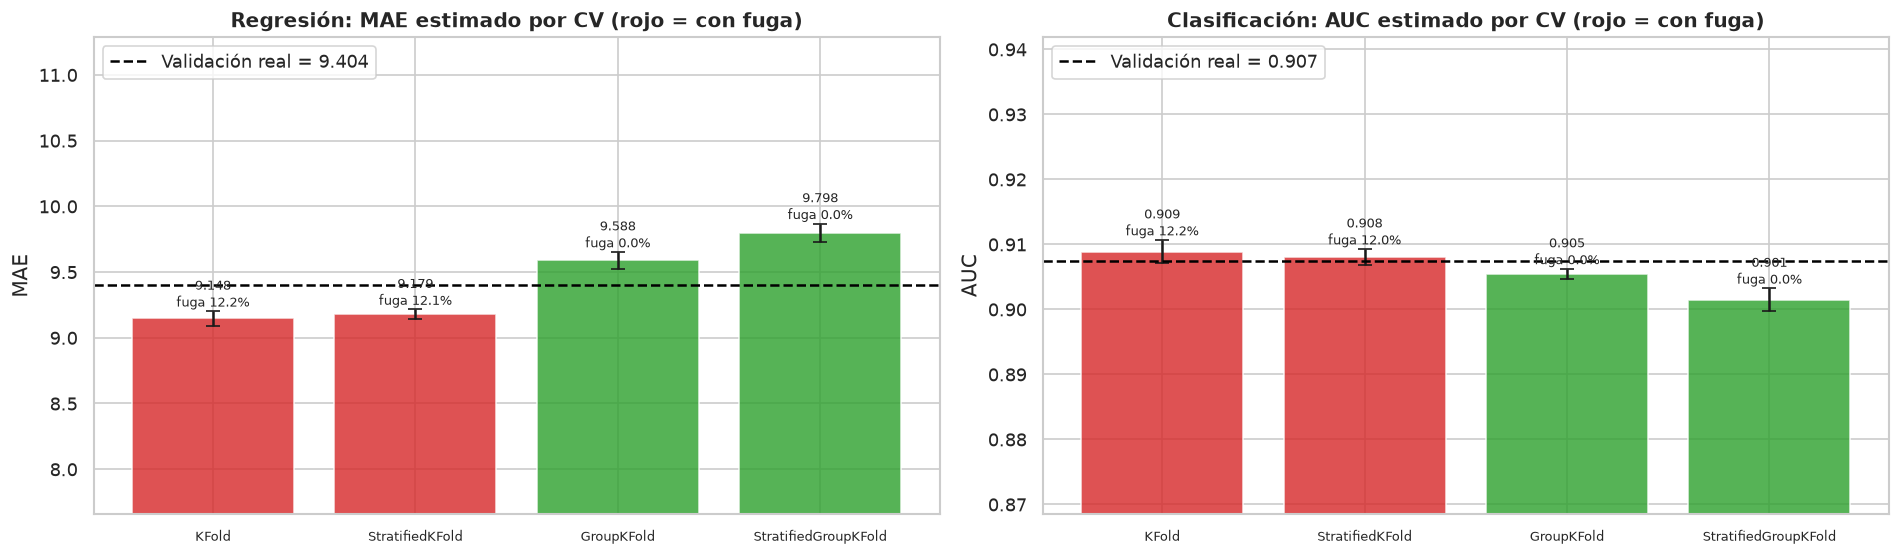

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (tarea, cfg) in zip(axes, TAREAS.items()):
    p = cfg['principal']
    sub = resultados_A[resultados_A['tarea'] == cfg['nombre']]
    etiquetas = [e.split(' (')[0] for e in sub['esquema']]
    colores = ['tab:red' if f > 1 else 'tab:green' for f in sub['fuga_%']]
    ax.bar(etiquetas, sub[f'{p}_cv'], yerr=sub[f'{p}_std'], color=colores, alpha=0.8, capsize=4)
    real = referencia_val[tarea][p]
    ax.axhline(real, color='black', linestyle='--', label=f'Validación real = {real:.3f}')
    for x, (v, f, e) in enumerate(zip(sub[f'{p}_cv'], sub['fuga_%'], sub[f'{p}_std'])):
        ax.text(x, v + e, f'{v:.3f}\nfuga {f:.1f}%', ha='center', va='bottom', fontsize=8)
    margen = (sub[f'{p}_cv'].max() - sub[f'{p}_cv'].min()) + abs(real) * 0.01
    ax.set_ylim(min(sub[f'{p}_cv'].min(), real) - 2 * margen, max(sub[f'{p}_cv'].max(), real) + 2 * margen)
    ax.set_title(f"{cfg['nombre']}: {p} estimado por CV (rojo = con fuga)", fontweight='bold')
    ax.set_ylabel(p); ax.legend(loc='upper left'); ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.savefig(IMAGES_DIR / '30_ep3_esquemas_cv.png', dpi=150, bbox_inches='tight')
plt.show()

#### Interpretación — bloque A

- **KFold y StratifiedKFold tienen fuga.** En ambos, el **12%** de las canciones de cada pliegue de
  validación tiene su misma clave artista + título en el entrenamiento del pliegue (reediciones).
  En GroupKFold y StratifiedGroupKFold la fuga es **0%**.
- **Por eso prometen más de lo que el modelo entrega.** En regresión estiman un MAE de 9,15 y 9,18,
  pero el modelo obtiene **9,40** en validación: subestiman el error en 0,26 y 0,23 puntos. En
  clasificación el efecto es menor (AUC 0,909 y 0,908 frente a 0,907 real), porque el AUC mide la
  capacidad de ordenar y no el tamaño del error.
- **Los esquemas agrupados son conservadores.** GroupKFold estima un MAE de 9,59 (0,18 peor que el
  real) y StratifiedGroupKFold 9,80. Es esperable: cada pliegue entrena con dos tercios del conjunto
  de ajuste (~38.000 canciones) y el *target encoding* ve menos canciones por artista. Para decidir,
  una estimación algo pesimista es preferible a una optimista.
- **Estratificar casi no cambia la estimación.** StratifiedKFold da prácticamente lo mismo que KFold
  (MAE 9,18 frente a 9,15; AUC 0,908 frente a 0,909), con algo menos de variación entre pliegues en
  regresión (desviación 0,037 frente a 0,055). Con 57.000 canciones los pliegues aleatorios ya
  quedan balanceados; estratificar importa más con pocos datos o clases muy escasas.
- **Conclusión:** para este dataset el esquema adecuado es **GroupKFold**, el mismo de la EP2.

## 4. Bloque B — LeaveOneOut en una submuestra

LOO entrena el modelo *n* veces, dejando fuera una canción cada vez. Sobre las 57.362 canciones de
ajuste es inviable, así que se toma una **submuestra aleatoria de 500 canciones** y se compara la
estimación de LOO con la de KFold de 5 y 10 pliegues y GroupKFold de 5. Como cada pliegue de LOO
tiene una sola canción, las métricas se calculan sobre todas las predicciones fuera de pliegue
(`cross_val_predict`) en los cuatro esquemas, para que sean comparables. El **desempeño real** de un
modelo entrenado con esas 500 canciones se mide en las 14.378 canciones de validación.

In [7]:
N_LOO = 500
idx_sub = np.random.RandomState(SEMILLA).choice(len(X_aj), N_LOO, replace=False)
X_sub, g_sub = X_aj.iloc[idx_sub], grupos_aj.iloc[idx_sub]
esquemas_sub = {
    'LeaveOneOut': LeaveOneOut(),
    'KFold 5': KFold(5, shuffle=True, random_state=SEMILLA),
    'KFold 10': KFold(10, shuffle=True, random_state=SEMILLA),
    'GroupKFold 5': GroupKFold(5),
}
filas_B = []
for tarea, cfg in TAREAS.items():
    y_sub = cfg['y_aj'].iloc[idx_sub]
    clases = np.unique(y_sub) if tarea == 'clasificacion' else None
    metodo = 'predict' if tarea == 'regresion' else 'predict_proba'
    for nombre, cv in esquemas_sub.items():
        def calcular(cv=cv):
            pred = cross_val_predict(crear_pipeline(clone(cfg['modelo_base'])), X_sub, y_sub, groups=g_sub,
                                     cv=cv, method=metodo, n_jobs=4)
            return metricas_desde_prediccion(tarea, y_sub, pred, clases)
        r = con_cache(f'B_{tarea}_{slug(nombre)}', calcular)
        filas_B.append({'tarea': cfg['nombre'], 'esquema': nombre,
                        'ajustes_del_modelo': cv.get_n_splits(X_sub, y_sub, g_sub), **r})
    real = con_cache(f'B_{tarea}_real_500',
                     lambda: metricas_validacion(tarea, crear_pipeline(clone(cfg['modelo_base'])).fit(X_sub, y_sub),
                                                 X_val, cfg['y_val']))
    filas_B.append({'tarea': cfg['nombre'], 'esquema': 'Real (500 canciones → validación)',
                    'ajustes_del_modelo': 1, **real})

resultados_B = pd.DataFrame(filas_B)
resultados_B.to_csv(PROCESSED_DIR / 'ep3_bloque_B_loo.csv', index=False)
for tarea, cfg in TAREAS.items():
    columnas = ['esquema', 'ajustes_del_modelo'] + list(cfg['scoring']) + ['segundos']
    columnas = [c for c in columnas if c in resultados_B.columns]
    print(f"\n{cfg['nombre']} — submuestra de {N_LOO} canciones")
    display(resultados_B[resultados_B['tarea'] == cfg['nombre']][columnas].set_index('esquema').round(4))

segundos_loo = resultados_B.loc[resultados_B['esquema'] == 'LeaveOneOut', 'segundos'].to_numpy()
print(f'\nCosto estimado de LOO con las {len(X_aj):,} canciones de ajuste: ~{len(X_aj)} ajustes por configuración; '
      f'con ~10 s por ajuste, ≈ {len(X_aj) * 10 / 86400:.1f} días por configuración.')

[caché] B_regresion_leaveoneout (cálculo original: 288 s)
[caché] B_regresion_kfold_5 (cálculo original: 4 s)
[caché] B_regresion_kfold_10 (cálculo original: 6 s)
[caché] B_regresion_groupkfold_5 (cálculo original: 4 s)
[caché] B_regresion_real_500 (cálculo original: 2 s)
[caché] B_clasificacion_leaveoneout (cálculo original: 221 s)
[caché] B_clasificacion_kfold_5 (cálculo original: 3 s)
[caché] B_clasificacion_kfold_10 (cálculo original: 5 s)
[caché] B_clasificacion_groupkfold_5 (cálculo original: 3 s)
[caché] B_clasificacion_real_500 (cálculo original: 1 s)

Regresión — submuestra de 500 canciones


,ajustes_del_modelo,MAE,RMSE,R2,segundos
esquema,,,,,
LeaveOneOut,500,17.4703,21.9361,-0.0611,288.2000
KFold 5,5,17.9093,22.0857,-0.0757,3.8000
KFold 10,10,17.5746,21.9771,-0.0651,6.2000
GroupKFold 5,5,18.0477,22.6415,-0.1305,3.8000
Real (500 canciones → validación),1,17.2521,21.7655,-0.1079,1.6000



Clasificación — submuestra de 500 canciones


,ajustes_del_modelo,AUC,F1_macro,Recall_alto,segundos
esquema,,,,,
LeaveOneOut,500,0.5969,0.3523,0.0152,221.2000
KFold 5,5,0.5991,0.3673,0.0303,2.7000
KFold 10,10,0.6088,0.3631,0.0152,4.8000
GroupKFold 5,5,0.5916,0.3668,0.0455,2.6000
Real (500 canciones → validación),1,0.6057,0.4008,0.0897,1.2000



Costo estimado de LOO con las 57,362 canciones de ajuste: ~57362 ajustes por configuración; con ~10 s por ajuste, ≈ 6.6 días por configuración.


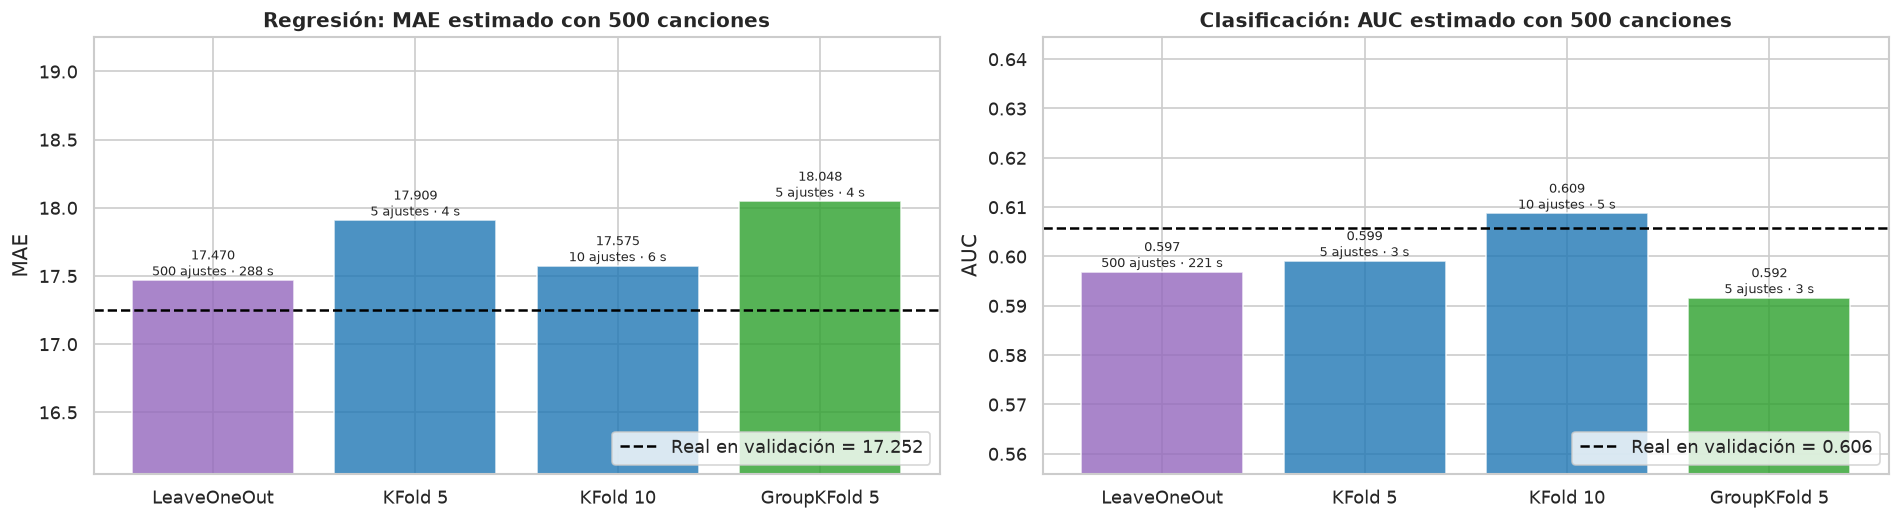

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (tarea, cfg) in zip(axes, TAREAS.items()):
    p = cfg['principal']
    sub = resultados_B[resultados_B['tarea'] == cfg['nombre']]
    estim = sub[sub['esquema'] != 'Real (500 canciones → validación)']
    real = sub.loc[sub['esquema'] == 'Real (500 canciones → validación)', p].iloc[0]
    ax.bar(estim['esquema'], estim[p], color=['tab:purple', 'tab:blue', 'tab:blue', 'tab:green'], alpha=0.8)
    ax.axhline(real, color='black', linestyle='--', label=f'Real en validación = {real:.3f}')
    for x, (v, s, n) in enumerate(zip(estim[p], estim['segundos'], estim['ajustes_del_modelo'])):
        ax.text(x, v, f'{v:.3f}\n{n} ajustes · {s:.0f} s', ha='center', va='bottom', fontsize=8)
    lo, hi = min(estim[p].min(), real), max(estim[p].max(), real)
    ax.set_ylim(lo - (hi - lo) * 1.5 - 0.01, hi + (hi - lo) * 1.5 + 0.01)
    ax.set_title(f"{cfg['nombre']}: {p} estimado con 500 canciones", fontweight='bold')
    ax.set_ylabel(p); ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMAGES_DIR / '31_ep3_leave_one_out.png', dpi=150, bbox_inches='tight')
plt.show()

#### Interpretación — bloque B

- Con solo 500 canciones el modelo es débil (MAE ≈ 17, al nivel del baseline; AUC ≈ 0,60). Este
  bloque compara **métodos de estimación**, no la calidad del modelo.
- **Regresión:** LOO estima un MAE de 17,47 frente a 17,25 real; KFold 10, 17,58; KFold 5, 17,91;
  GroupKFold 5, 18,05. LOO es el más cercano, como predice la teoría (entrena con 499 de 500
  canciones, casi sin sesgo), pero KFold 10 queda muy cerca.
- **Clasificación:** LOO estima un AUC de 0,597, KFold 5 0,599 y KFold 10 0,609, frente a 0,606
  real. Aquí LOO no es mejor: con una canción por pliegue su estimación es muy variable.
- **Costo:** LOO necesitó **500 ajustes** (288 s en regresión y 221 s en clasificación), frente a 5
  ajustes y unos 4 s de KFold 5: unas **70 veces más caro**. Con las 57.362 canciones de ajuste
  serían ≈ 6,6 días por configuración. Además, LOO no agrupa reediciones.
- **Conclusión:** LOO no es adecuado para este caso. KFold de 5 a 10 pliegues (agrupado) entrega
  estimaciones equivalentes por una fracción del costo.

## 5. Bloque C — GridSearchCV vs. RandomizedSearchCV en cada esquema (Boosting)

Los dos métodos tienen **el mismo presupuesto: 8 configuraciones × 3 pliegues**, y parten de los
hiperparámetros de la EP2.

| Hiperparámetro de HistGradientBoosting | Qué controla | GridSearchCV (2 × 2 × 2 = 8) | RandomizedSearchCV (8 sorteos) |
|---|---|---|---|
| `learning_rate` | Cuánto corrige cada árbol nuevo | {0,03; 0,06} | log-uniforme [0,02; 0,15] |
| `max_leaf_nodes` | Complejidad de cada árbol | {31; 63} | entero [15; 127] |
| `min_samples_leaf` | Mínimo de canciones por hoja (regulariza) | {20; 50} | entero [10; 100] |
| `l2_regularization` | Penaliza hojas con valores extremos | fijo en el valor EP2 | uniforme [0; 1,5] |
| `max_iter` | Máximo de árboles (con parada temprana) | fijo en el valor EP2 | fijo en el valor EP2 |

La grilla prueba combinaciones exactas de pocos valores; la búsqueda aleatoria, con el mismo
costo, explora además `l2_regularization` y valores intermedios.

In [9]:
ESPACIOS = {
    ('Boosting', 'GridSearchCV'): {
        'modelo__learning_rate': [0.03, 0.06],
        'modelo__max_leaf_nodes': [31, 63],
        'modelo__min_samples_leaf': [20, 50],
    },
    ('Boosting', 'RandomizedSearchCV'): {
        'modelo__learning_rate': loguniform(0.02, 0.15),
        'modelo__max_leaf_nodes': randint(15, 128),
        'modelo__min_samples_leaf': randint(10, 101),
        'modelo__l2_regularization': uniform(0.0, 1.5),
    },
    ('Bagging', 'GridSearchCV'): {
        'modelo__n_estimators': [5, 10],
        'modelo__max_samples': [0.5, 0.8],
    },
    ('Bagging', 'RandomizedSearchCV'): {
        'modelo__n_estimators': randint(5, 13),
        'modelo__max_samples': uniform(0.4, 0.5),
        'modelo__max_features': uniform(0.7, 0.3),
    },
}
N_ITER = {'Boosting': 8, 'Bagging': 4}
DESCRIPCION_ESPACIO = {
    ('Boosting', 'GridSearchCV'): 'learning_rate {0,03; 0,06} × max_leaf_nodes {31; 63} × min_samples_leaf {20; 50}',
    ('Boosting', 'RandomizedSearchCV'): '8 sorteos: learning_rate log-U[0,02; 0,15], max_leaf_nodes [15; 127], '
                                        'min_samples_leaf [10; 100], l2_regularization U[0; 1,5]',
    ('Bagging', 'GridSearchCV'): 'n_estimators {5; 10} × max_samples {0,5; 0,8}',
    ('Bagging', 'RandomizedSearchCV'): '4 sorteos: n_estimators [5; 12], max_samples U[0,4; 0,9], '
                                       'max_features U[0,7; 1,0]',
}
MEMORIA = joblib.Memory(tempfile.mkdtemp(prefix='ep3_prep_'), verbose=0)


def crear_modelo(tarea, estrategia):
    cfg = TAREAS[tarea]
    if estrategia == 'Boosting':
        return clone(cfg['modelo_base'])
    return cfg['bagging'](estimator=clone(cfg['modelo_base']), bootstrap=True, n_jobs=1, random_state=SEMILLA)


def ejecutar_busqueda(tarea, estrategia, metodo, splits):
    cfg = TAREAS[tarea]
    pipe = crear_pipeline(crear_modelo(tarea, estrategia), MEMORIA)
    espacio = ESPACIOS[(estrategia, metodo)]
    comunes = dict(scoring=cfg['scoring'], refit=cfg['principal'], cv=splits, n_jobs=1, error_score='raise')
    if metodo == 'GridSearchCV':
        busqueda = GridSearchCV(pipe, espacio, **comunes)
    else:
        busqueda = RandomizedSearchCV(pipe, espacio, n_iter=N_ITER[estrategia], random_state=SEMILLA, **comunes)
    busqueda.fit(X_aj, cfg['y_aj'])
    MEMORIA.clear(warn=False)
    res = pd.DataFrame(busqueda.cv_results_)
    detalle = pd.DataFrame({'hiperparametros': res['params'].map(formatear_params),
                            **{f'{m}_cv': signo(cfg['scoring'], m) * res[f'mean_test_{m}'] for m in cfg['scoring']},
                            'segundos_ajuste': res['mean_fit_time']})
    mejor = res.iloc[busqueda.best_index_]
    return {'mejores_parametros': {k.replace('modelo__', ''): v for k, v in busqueda.best_params_.items()},
            **{f'{m}_cv': signo(cfg['scoring'], m) * mejor[f'mean_test_{m}'] for m in cfg['scoring']},
            **{f'{m}_std': mejor[f'std_test_{m}'] for m in cfg['scoring']},
            'configuraciones': len(res), 'detalle': detalle,
            'validacion': metricas_validacion(tarea, busqueda.best_estimator_, X_val, cfg['y_val'])}


def fila_busqueda(tarea, estrategia, metodo, esquema, r, fuga):
    cfg = TAREAS[tarea]
    return {'tarea': cfg['nombre'], 'estrategia': estrategia, 'metodo': metodo, 'esquema': esquema,
            'fuga_%': fuga, 'configuraciones': r['configuraciones'],
            'espacio': DESCRIPCION_ESPACIO[(estrategia, metodo)],
            'hiperparametros_elegidos': formatear_params(r['mejores_parametros']),
            'params': r['mejores_parametros'],
            **{f'{m}_cv': r[f'{m}_cv'] for m in cfg['scoring']},
            f"{cfg['principal']}_std": r[f"{cfg['principal']}_std"],
            **{f'val_{m}': v for m, v in r['validacion'].items()}, 'segundos': r['segundos']}


ESQUEMAS_BUSQUEDA = ['KFold (estándar)', 'StratifiedKFold (estratificado)', 'GroupKFold (agrupado)']
busquedas = {}
filas_C = []
for tarea in TAREAS:
    esquemas = crear_esquemas(tarea)
    for esquema in ESQUEMAS_BUSQUEDA:
        for metodo in ['GridSearchCV', 'RandomizedSearchCV']:
            clave = f'C_{tarea}_boosting_{slug(metodo)}_{slug(esquema)}'
            r = con_cache(clave, lambda: ejecutar_busqueda(tarea, 'Boosting', metodo, esquemas[esquema]))
            busquedas[clave] = r
            filas_C.append(fila_busqueda(tarea, 'Boosting', metodo, esquema, r, porcentaje_fuga(esquemas[esquema])))
resultados_C = pd.DataFrame(filas_C)
print('Bloque C completo.')

[caché] C_regresion_boosting_gridsearchcv_kfold_est_ndar (cálculo original: 172 s)
[caché] C_regresion_boosting_randomizedsearchcv_kfold_est_ndar (cálculo original: 184 s)
[caché] C_regresion_boosting_gridsearchcv_stratifiedkfold_estratificado (cálculo original: 168 s)
[caché] C_regresion_boosting_randomizedsearchcv_stratifiedkfold_estratificado (cálculo original: 189 s)
[caché] C_regresion_boosting_gridsearchcv_groupkfold_agrupado (cálculo original: 173 s)
[caché] C_regresion_boosting_randomizedsearchcv_groupkfold_agrupado (cálculo original: 199 s)


[caché] C_clasificacion_boosting_gridsearchcv_kfold_est_ndar (cálculo original: 268 s)
[caché] C_clasificacion_boosting_randomizedsearchcv_kfold_est_ndar (cálculo original: 269 s)
[caché] C_clasificacion_boosting_gridsearchcv_stratifiedkfold_estratificado (cálculo original: 272 s)
[caché] C_clasificacion_boosting_randomizedsearchcv_stratifiedkfold_estratificado (cálculo original: 282 s)
[caché] C_clasificacion_boosting_gridsearchcv_groupkfold_agrupado (cálculo original: 277 s)
[caché] C_clasificacion_boosting_randomizedsearchcv_groupkfold_agrupado (cálculo original: 278 s)
Bloque C completo.


In [10]:
for tarea, cfg in TAREAS.items():
    p, s = cfg['principal'], cfg['secundaria']
    sub = resultados_C[resultados_C['tarea'] == cfg['nombre']]
    print(f"\n{cfg['nombre']} — Boosting: hiperparámetros elegidos por cada método y esquema")
    display(sub[['metodo', 'esquema', 'fuga_%', 'hiperparametros_elegidos', f'{p}_cv', f'val_{p}', f'val_{s}',
                 'segundos']].set_index(['metodo', 'esquema']).round(4))

# Ejemplo de todas las configuraciones probadas por una búsqueda (regresión, GroupKFold)
for metodo in ['GridSearchCV', 'RandomizedSearchCV']:
    print(f'\nRegresión — {metodo} con GroupKFold: las 8 configuraciones evaluadas')
    display(busquedas[f'C_regresion_boosting_{slug(metodo)}_groupkfold_agrupado']['detalle']
            .sort_values('MAE_cv').round(4).reset_index(drop=True))


Regresión — Boosting: hiperparámetros elegidos por cada método y esquema


,,fuga_%,hiperparametros_elegidos,MAE_cv,val_MAE,val_RMSE,segundos
metodo,esquema,,,,,,
GridSearchCV,KFold (estándar),12.2259,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",9.1478,9.4039,14.3765,172.4000
RandomizedSearchCV,KFold (estándar),12.2259,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.2195,9.4161,14.3916,183.9000
GridSearchCV,StratifiedKFold (estratificado),12.1457,"learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=20",9.1651,9.3987,14.4354,168.1000
RandomizedSearchCV,StratifiedKFold (estratificado),12.1457,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.2103,9.4161,14.3916,189.3000
GridSearchCV,GroupKFold (agrupado),0.0000,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",9.5884,9.4039,14.3765,173.4000
RandomizedSearchCV,GroupKFold (agrupado),0.0000,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.6192,9.4161,14.3916,198.6000



Clasificación — Boosting: hiperparámetros elegidos por cada método y esquema


,,fuga_%,hiperparametros_elegidos,AUC_cv,val_AUC,val_F1_macro,segundos
metodo,esquema,,,,,,
GridSearchCV,KFold (estándar),12.2259,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9096,0.9081,0.7084,267.9000
RandomizedSearchCV,KFold (estándar),12.2259,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9094,0.9083,0.7088,268.6000
GridSearchCV,StratifiedKFold (estratificado),12.0149,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9085,0.9081,0.7084,272.4000
RandomizedSearchCV,StratifiedKFold (estratificado),12.0149,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9084,0.9083,0.7088,281.6000
GridSearchCV,GroupKFold (agrupado),0.0000,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9062,0.9081,0.7084,276.6000
RandomizedSearchCV,GroupKFold (agrupado),0.0000,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9057,0.9083,0.7088,278.0000



Regresión — GridSearchCV con GroupKFold: las 8 configuraciones evaluadas


,hiperparametros,MAE_cv,RMSE_cv,R2_cv,segundos_ajuste
0,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",9.5884,14.7291,0.4881,8.3488
1,"learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=20",9.6062,14.7499,0.4866,4.5493
2,"learning_rate=0.06, max_leaf_nodes=31, min_samples_leaf=20",9.6339,14.7517,0.4865,5.4195
3,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=50",9.6699,14.7359,0.4876,8.1851
4,"learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=20",9.6874,14.7164,0.4890,7.1430
5,"learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=50",9.6974,14.7620,0.4858,5.4887
6,"learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=50",9.7197,14.7304,0.4880,6.3976
7,"learning_rate=0.06, max_leaf_nodes=31, min_samples_leaf=50",9.7236,14.7806,0.4845,5.5584



Regresión — RandomizedSearchCV con GroupKFold: las 8 configuraciones evaluadas


,hiperparametros,MAE_cv,RMSE_cv,R2_cv,segundos_ajuste
0,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.6192,14.7201,0.4887,11.4092
1,"l2_regularization=0.319, learning_rate=0.0288, max_leaf_nodes=35, min_samples_leaf=42",9.7120,14.7393,0.4874,6.6759
2,"l2_regularization=0.0871, learning_rate=0.115, max_leaf_nodes=114, min_samples_leaf=33",9.7313,14.8293,0.4811,3.7129
3,"l2_regularization=0.55, learning_rate=0.0501, max_leaf_nodes=61, min_samples_leaf=71",9.7768,14.8228,0.4815,7.2464
4,"l2_regularization=0.437, learning_rate=0.0686, max_leaf_nodes=56, min_samples_leaf=69",9.7890,14.8120,0.4823,5.4062
5,"l2_regularization=0.898, learning_rate=0.0274, max_leaf_nodes=97, min_samples_leaf=96",9.7964,14.8094,0.4825,11.9270
6,"l2_regularization=0.456, learning_rate=0.0576, max_leaf_nodes=122, min_samples_leaf=98",9.8928,14.8880,0.4770,6.8070
7,"l2_regularization=0.562, learning_rate=0.136, max_leaf_nodes=121, min_samples_leaf=81",9.9923,15.0085,0.4685,4.8350


#### Interpretación — bloque C

**Hiperparámetros elegidos (Boosting):**

| Método | Esquema | Regresión | Clasificación |
|---|---|---|---|
| GridSearchCV | KFold y GroupKFold | learning_rate 0,03 · max_leaf_nodes 63 · min_samples_leaf 20 (= EP2) | learning_rate 0,03 · max_leaf_nodes 63 · min_samples_leaf 20 |
| GridSearchCV | StratifiedKFold | learning_rate **0,06** · max_leaf_nodes 63 · min_samples_leaf 20 | learning_rate 0,03 · max_leaf_nodes 63 · min_samples_leaf 20 |
| RandomizedSearchCV | los tres | learning_rate 0,0224 · max_leaf_nodes 102 · min_samples_leaf 39 · l2_regularization 0,976 | la misma configuración |

- **Regresión: ninguna búsqueda mejora a la EP2.** La mejor configuración de la grilla coincide con
  los hiperparámetros de la EP2 (MAE de validación 9,404). La variante con learning_rate 0,06 baja el
  MAE en 0,005, pero empeora el RMSE (14,44 frente a 14,38). La configuración de la búsqueda
  aleatoria obtiene un MAE de 9,416, levemente peor. Los hiperparámetros de la EP2 ya estaban en el
  óptimo de estos espacios.
- **Clasificación: ambas búsquedas mejoran levemente a la EP2.** El AUC de validación pasa de 0,9075
  (EP2) a 0,9081 con la grilla (`min_samples_leaf` 50 → 20) y a **0,9083** con la búsqueda
  aleatoria (árboles más grandes, 102 hojas, compensados con regularización L2 de 0,976 y una tasa de
  aprendizaje menor). El F1 macro sube de 0,707 a 0,709.
- **El esquema cambió la estimación, no la elección.** En 5 de los 6 casos los tres esquemas
  eligieron la misma configuración. La búsqueda aleatoria usa una semilla fija, así que evalúa las
  mismas 8 configuraciones en todos los esquemas; el esquema solo cambia su puntaje. Las estimaciones
  con fuga siguen siendo optimistas: por ejemplo, la grilla con KFold estima un MAE de 9,15 y la
  misma configuración obtiene 9,40 en validación.
- **Grilla frente a búsqueda aleatoria:** con el mismo presupuesto (8 configuraciones × 3 pliegues,
  entre 170 y 280 s por búsqueda), la búsqueda aleatoria encontró la mejor configuración en
  clasificación, porque exploró `l2_regularization` y tamaños de árbol fuera de la grilla. En
  regresión ganó la grilla, centrada en los valores de la EP2.

## 6. Bloque D — Bagging vs. Boosting

Se envuelve el HistGradientBoosting de la EP2 (con sus hiperparámetros) en un `Bagging`: se
entrenan varias copias, cada una con una muestra bootstrap distinta (y, en la búsqueda aleatoria,
con una fracción de las variables), y se promedian sus predicciones o probabilidades. Se usa
GroupKFold, el esquema sin fuga, con ambos métodos de búsqueda.

| Hiperparámetro de Bagging | Qué controla | GridSearchCV (2 × 2 = 4) | RandomizedSearchCV (4 sorteos) |
|---|---|---|---|
| `n_estimators` | Cantidad de modelos promediados | {5; 10} | entero [5; 12] |
| `max_samples` | Fracción de canciones de cada muestra bootstrap | {0,5; 0,8} | uniforme [0,4; 0,9] |
| `max_features` | Fracción de variables que ve cada modelo | 1,0 (todas) | uniforme [0,7; 1,0] |

Cada configuración de Bagging cuesta entre 5 y 12 entrenamientos del modelo base; por eso el
presupuesto es de 4 configuraciones por método.

In [11]:
filas_D = []
for tarea in TAREAS:
    splits = crear_esquemas(tarea)['GroupKFold (agrupado)']
    for metodo in ['GridSearchCV', 'RandomizedSearchCV']:
        clave = f'D_{tarea}_bagging_{slug(metodo)}_groupkfold'
        r = con_cache(clave, lambda: ejecutar_busqueda(tarea, 'Bagging', metodo, splits))
        busquedas[clave] = r
        filas_D.append(fila_busqueda(tarea, 'Bagging', metodo, 'GroupKFold (agrupado)', r, porcentaje_fuga(splits)))
resultados_D = pd.DataFrame(filas_D)

for tarea, cfg in TAREAS.items():
    p, s = cfg['principal'], cfg['secundaria']
    sub = resultados_D[resultados_D['tarea'] == cfg['nombre']]
    print(f"\n{cfg['nombre']} — Bagging sobre HistGradientBoosting")
    display(sub[['metodo', 'hiperparametros_elegidos', f'{p}_cv', f'val_{p}', f'val_{s}', 'segundos']]
            .set_index('metodo').round(4))
    for metodo in ['GridSearchCV', 'RandomizedSearchCV']:
        print(f'  Configuraciones de {metodo}:')
        display(busquedas[f'D_{tarea}_bagging_{slug(metodo)}_groupkfold']['detalle'].round(4))

[caché] D_regresion_bagging_gridsearchcv_groupkfold (cálculo original: 745 s)
[caché] D_regresion_bagging_randomizedsearchcv_groupkfold (cálculo original: 606 s)


[caché] D_clasificacion_bagging_gridsearchcv_groupkfold (cálculo original: 1179 s)
[caché] D_clasificacion_bagging_randomizedsearchcv_groupkfold (cálculo original: 942 s)

Regresión — Bagging sobre HistGradientBoosting


,hiperparametros_elegidos,MAE_cv,val_MAE,val_RMSE,segundos
metodo,,,,,
GridSearchCV,"max_samples=0.8, n_estimators=10",9.6868,9.5381,14.3696,745.3000
RandomizedSearchCV,"max_features=0.934, max_samples=0.698, n_estimators=6",9.9261,9.7952,14.4669,605.7000


  Configuraciones de GridSearchCV:


,hiperparametros,MAE_cv,RMSE_cv,R2_cv,segundos_ajuste
0,"max_samples=0.5, n_estimators=5",9.8379,14.7387,0.4874,31.7900
1,"max_samples=0.5, n_estimators=10",9.8127,14.7050,0.4898,63.4196
2,"max_samples=0.8, n_estimators=5",9.7008,14.6850,0.4911,41.5449
3,"max_samples=0.8, n_estimators=10",9.6868,14.6500,0.4936,75.3252


...

,hiperparametros_elegidos,AUC_cv,val_AUC,val_F1_macro,segundos
metodo,,,,,
GridSearchCV,"max_samples=0.8, n_estimators=10",0.9057,0.9074,0.7121,"1,178.8000"
RandomizedSearchCV,"max_features=0.934, max_samples=0.698, n_estimators=6",0.9051,0.9070,0.7033,942.0000


  Configuraciones de GridSearchCV:


,hiperparametros,AUC_cv,F1_macro_cv,Recall_alto_cv,segundos_ajuste
0,"max_samples=0.5, n_estimators=5",0.9034,0.6970,0.3734,51.8668
1,"max_samples=0.5, n_estimators=10",0.9045,0.6973,0.3749,102.9288
2,"max_samples=0.8, n_estimators=5",0.9051,0.7009,0.3871,55.0496
3,"max_samples=0.8, n_estimators=10",0.9057,0.7013,0.3868,109.8915


  Configuraciones de RandomizedSearchCV:


,hiperparametros,AUC_cv,F1_macro_cv,Recall_alto_cv,segundos_ajuste
0,"max_features=0.812, max_samples=0.875, n_estimators=7",0.9035,0.6900,0.3394,63.9372
1,"max_features=0.934, max_samples=0.698, n_estimators=6",0.9051,0.6947,0.3586,59.2174
2,"max_features=0.747, max_samples=0.429, n_estimators=12",0.9015,0.6789,0.3054,85.7581
3,"max_features=0.8, max_samples=0.471, n_estimators=7",0.9018,0.6866,0.3300,56.5709


#### Interpretación — bloque D

- **Bagging no mejora al modelo de boosting en ninguna tarea.** En regresión, el mejor Bagging
  (grilla: 10 modelos, 80% de las canciones cada uno) obtiene un MAE de validación de **9,54**,
  frente a 9,40 del boosting solo. La versión aleatoria (6 modelos, 70% de las canciones y 93% de las
  variables) obtiene 9,80. En clasificación, el AUC es de 0,9074 (grilla) y 0,9070 (aleatoria),
  frente a 0,9075 de la EP2 y 0,9083 del mejor boosting.
- **Cuesta entre 4 y 6 veces más:** entre 606 y 1.179 s por búsqueda, frente a 170–280 s del
  boosting.
- **Por qué no ayuda:** Bagging reduce la **varianza**, y HistGradientBoosting, con parada temprana y
  regularización, ya tiene poca (el AUC varía apenas 0,001 entre pliegues). En cambio, cada copia ve
  solo entre el 50% y el 80% de las canciones, lo que **aumenta el sesgo**. Además, con
  `max_features` < 1 algunas copias pierden variables clave, como la del artista: la configuración
  que usó el 75% de las variables fue la peor (MAE de CV 10,73). Las configuraciones mejoran a
  medida que cada copia ve más datos y hay más copias, es decir, a medida que se parecen al modelo
  único.
- El F1 macro del Bagging en clasificación (0,712) es algo mayor, pero la métrica de selección
  definida desde la EP2 es el ROC-AUC.

## 7. Comparación de todas las combinaciones y elección

Se reúnen, por tarea, las 9 combinaciones (referencia EP2 con `cross_validate`, 6 de Boosting y 2
de Bagging). La referencia usa la estimación de GroupKFold del bloque A. El orden lo da la métrica
principal en **validación**, la vara común (ver 1.2).

In [12]:
def fila_referencia(tarea):
    cfg = TAREAS[tarea]
    a = resultados_A[(resultados_A['tarea'] == cfg['nombre']) & (resultados_A['esquema'] == 'GroupKFold (agrupado)')].iloc[0]
    return {'tarea': cfg['nombre'], 'estrategia': 'Boosting', 'metodo': 'CrossValidation (sin búsqueda)',
            'esquema': 'GroupKFold (agrupado)', 'fuga_%': a['fuga_%'], 'configuraciones': 1,
            'espacio': 'Hiperparámetros fijos de la EP2', 'hiperparametros_elegidos': formatear_params(cfg['params_ep2']),
            'params': {}, **{f'{m}_cv': a[f'{m}_cv'] for m in cfg['scoring']},
            f"{cfg['principal']}_std": a[f"{cfg['principal']}_std"],
            **{f'val_{m}': v for m, v in referencia_val[tarea].items() if m != 'segundos'}, 'segundos': a['segundos']}


tablas_finales, ganadores = {}, {}
for tarea, cfg in TAREAS.items():
    p, s = cfg['principal'], cfg['secundaria']
    tabla = pd.DataFrame([fila_referencia(tarea)]
                         + resultados_C[resultados_C['tarea'] == cfg['nombre']].to_dict('records')
                         + resultados_D[resultados_D['tarea'] == cfg['nombre']].to_dict('records'))
    decimales = 2 if tarea == 'regresion' else 3
    tabla['_principal'] = tabla[f'val_{p}'].round(decimales) * (-1 if cfg['mayor_es_mejor'] else 1)
    tabla['_secundaria'] = tabla[f'val_{s}'] * (-1 if cfg['mayor_es_mejor'] else 1)
    tabla = tabla.sort_values(['_principal', '_secundaria', 'fuga_%', 'segundos']).reset_index(drop=True)
    tabla.index = tabla.index + 1
    tabla.index.name = 'ranking'
    ref = tabla.loc[tabla['metodo'] == 'CrossValidation (sin búsqueda)', f'val_{p}'].iloc[0]
    tabla[f'mejora_vs_EP2_{p}'] = (tabla[f'val_{p}'] - ref) * (1 if cfg['mayor_es_mejor'] else -1)
    tablas_finales[tarea] = tabla
    ganadores[tarea] = tabla.iloc[0]
    columnas = ['estrategia', 'metodo', 'esquema', 'configuraciones', 'hiperparametros_elegidos',
                f'{p}_cv', f'val_{p}', f'val_{s}', f'mejora_vs_EP2_{p}', 'segundos']
    print(f"\n{cfg['nombre']} — ranking por {p} en validación")
    display(tabla[columnas].round(4))
    g = ganadores[tarea]
    print(f"GANADORA: {g['estrategia']} + {g['metodo']} + {g['esquema']} -> {g['hiperparametros_elegidos']}")
    print(f"  {p} validación = {g[f'val_{p}']:.4f} (EP2: {ref:.4f}; mejora = {g[f'mejora_vs_EP2_{p}']:+.4f})")

pd.concat(tablas_finales.values()).drop(columns=['params', '_principal', '_secundaria']).to_csv(
    PROCESSED_DIR / 'ep3_comparacion_combinaciones.csv')


Regresión — ranking por MAE en validación


,estrategia,metodo,esquema,configuraciones,hiperparametros_elegidos,MAE_cv,val_MAE,val_RMSE,mejora_vs_EP2_MAE,segundos
ranking,,,,,,,,,,
1,Boosting,CrossValidation (sin búsqueda),GroupKFold (agrupado),1,"l2_regularization=0.5, learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20",9.5884,9.4039,14.3765,-0.0000,25.7000
2,Boosting,GridSearchCV,GroupKFold (agrupado),8,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",9.5884,9.4039,14.3765,-0.0000,173.4000
3,Boosting,GridSearchCV,KFold (estándar),8,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",9.1478,9.4039,14.3765,-0.0000,172.4000
4,Boosting,GridSearchCV,StratifiedKFold (estratificado),8,"learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=20",9.1651,9.3987,14.4354,0.0053,168.1000
5,Boosting,RandomizedSearchCV,GroupKFold (agrupado),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.6192,9.4161,14.3916,-0.0122,198.6000
6,Boosting,RandomizedSearchCV,StratifiedKFold (estratificado),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.2103,9.4161,14.3916,-0.0122,189.3000
7,Boosting,RandomizedSearchCV,KFold (estándar),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",9.2195,9.4161,14.3916,-0.0122,183.9000
8,Bagging,GridSearchCV,GroupKFold (agrupado),4,"max_samples=0.8, n_estimators=10",9.6868,9.5381,14.3696,-0.1342,745.3000
9,Bagging,RandomizedSearchCV,GroupKFold (agrupado),4,"max_features=0.934, max_samples=0.698, n_estimators=6",9.9261,9.7952,14.4669,-0.3913,605.7000


GANADORA: Boosting + CrossValidation (sin búsqueda) + GroupKFold (agrupado) -> l2_regularization=0.5, learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20
  MAE validación = 9.4039 (EP2: 9.4039; mejora = -0.0000)

Clasificación — ranking por AUC en validación


,estrategia,metodo,esquema,configuraciones,hiperparametros_elegidos,AUC_cv,val_AUC,val_F1_macro,mejora_vs_EP2_AUC,segundos
ranking,,,,,,,,,,
1,Boosting,RandomizedSearchCV,GroupKFold (agrupado),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9057,0.9083,0.7088,0.0008,278.0000
2,Boosting,RandomizedSearchCV,StratifiedKFold (estratificado),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9084,0.9083,0.7088,0.0008,281.6000
3,Boosting,RandomizedSearchCV,KFold (estándar),8,"l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39",0.9094,0.9083,0.7088,0.0008,268.6000
4,Boosting,GridSearchCV,GroupKFold (agrupado),8,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9062,0.9081,0.7084,0.0007,276.6000
5,Boosting,GridSearchCV,StratifiedKFold (estratificado),8,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9085,0.9081,0.7084,0.0007,272.4000
6,Boosting,GridSearchCV,KFold (estándar),8,"learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20",0.9096,0.9081,0.7084,0.0007,267.9000
7,Bagging,GridSearchCV,GroupKFold (agrupado),4,"max_samples=0.8, n_estimators=10",0.9057,0.9074,0.7121,-0.0001,"1,178.8000"
8,Boosting,CrossValidation (sin búsqueda),GroupKFold (agrupado),1,"l2_regularization=0, learning_rate=0.03, max_iter=300, max_leaf_nodes=63, min_samples_leaf=50",0.9055,0.9075,0.7068,0.0000,40.5000
9,Bagging,RandomizedSearchCV,GroupKFold (agrupado),4,"max_features=0.934, max_samples=0.698, n_estimators=6",0.9051,0.9070,0.7033,-0.0004,942.0000


GANADORA: Boosting + RandomizedSearchCV + GroupKFold (agrupado) -> l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39
  AUC validación = 0.9083 (EP2: 0.9075; mejora = +0.0008)


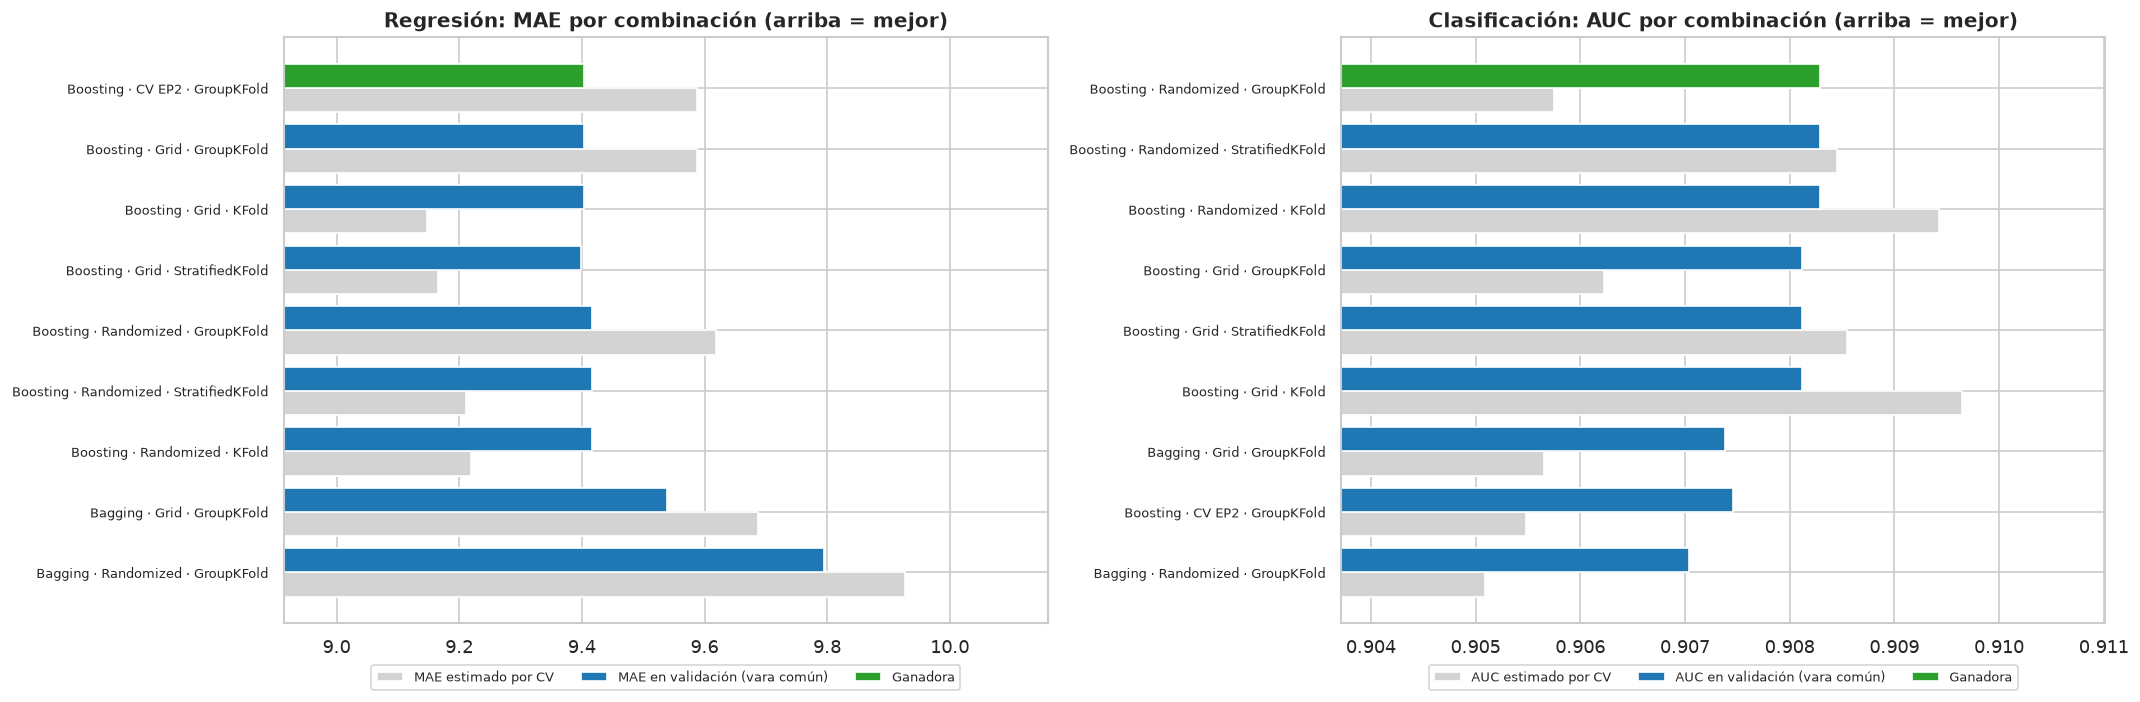

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (tarea, cfg) in zip(axes, TAREAS.items()):
    p = cfg['principal']
    t = tablas_finales[tarea].iloc[::-1]
    etiquetas = [f"{e} · {m.replace('SearchCV', '').replace('CrossValidation (sin búsqueda)', 'CV EP2')}"
                 f" · {q.split(' (')[0]}" for e, m, q in zip(t['estrategia'], t['metodo'], t['esquema'])]
    y = np.arange(len(t))
    ax.barh(y - 0.2, t[f'{p}_cv'], height=0.4, color='lightgray', label=f'{p} estimado por CV')
    ax.barh(y + 0.2, t[f'val_{p}'], height=0.4, color='tab:blue', label=f'{p} en validación (vara común)')
    ax.barh(len(t) - 1 + 0.2, t[f'val_{p}'].iloc[-1], height=0.4, color='tab:green', label='Ganadora')
    ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=8)
    valores = pd.concat([t[f'{p}_cv'], t[f'val_{p}']])
    rango = valores.max() - valores.min()
    ax.set_xlim(valores.min() - rango * 0.3, valores.max() + rango * 0.3)
    ax.set_title(f"{cfg['nombre']}: {p} por combinación (arriba = mejor)", fontweight='bold')
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / '32_ep3_comparacion_combinaciones.png', dpi=150, bbox_inches='tight')
plt.show()

#### Elección

- **Regresión → se mantiene la configuración de la EP2** (Boosting, sin búsqueda, validada con
  GroupKFold). Empata en MAE redondeado (9,40) con la grilla bajo KFold y GroupKFold, que eligieron
  exactamente los mismos valores, y con la grilla bajo StratifiedKFold (learning_rate 0,06), que tiene
  peor RMSE. A igualdad de resultado, se prefiere la opción más simple y barata (25 s frente a
  ~170 s).
- **Clasificación → RandomizedSearchCV + GroupKFold + Boosting:** HistGradientBoostingClassifier con
  `learning_rate` 0,0224, `max_leaf_nodes` 102, `min_samples_leaf` 39, `l2_regularization` 0,976 y
  `max_iter` 300 (con parada temprana). AUC de validación: 0,9083 frente a 0,9075 de la EP2. La misma
  configuración la eligieron KFold y StratifiedKFold; el desempate favorece al esquema sin fuga.
- **Magnitud:** +0,0008 de AUC, del mismo orden que la variación entre pliegues (0,0008–0,0018). Es
  una mejora pequeña; la prueba final indica si se sostiene.

## 8. Evaluación final en prueba

La combinación ganadora de cada tarea se reentrena con las **71.740 canciones** de entrenamiento y se
evalúa **una sola vez** en el conjunto de prueba de la EP2. Se compara con los modelos de la EP2
guardados en `models/`, medidos con el mismo código.

En clasificación, el umbral de la clase "alto" se recalcula para el modelo ganador con la misma regla
de la EP2: el mayor umbral *u* que logra recall de "alto" ≥ 0,60 con probabilidades fuera de pliegue
del entrenamiento (GroupKFold de 3 pliegues). El conjunto de prueba no participa.

In [14]:
def modelo_ganador(tarea):
    g = ganadores[tarea]
    modelo = crear_modelo(tarea, g['estrategia'])
    if g['params']:
        modelo.set_params(**g['params'])
    return crear_pipeline(modelo)


def predecir_con_umbral(proba, umbral, clases):
    clases = list(clases)
    i_alto = clases.index('alto')
    resto = [i for i in range(len(clases)) if i != i_alto]
    pred = np.array(clases, dtype=object)[np.array(resto)[proba[:, resto].argmax(axis=1)]]
    return np.where(proba[:, i_alto] >= umbral, 'alto', pred)


filas_test = []
modelos_ep3 = {}
for tarea, cfg in TAREAS.items():
    es_referencia = ganadores[tarea]['metodo'] == 'CrossValidation (sin búsqueda)'

    def entrenar():
        modelo = modelo_ganador(tarea).fit(X_train, cfg['y_train'])
        salida = {'modelo': modelo}
        if tarea == 'clasificacion':
            proba_oof = cross_val_predict(modelo_ganador(tarea), X_train, cfg['y_train'], groups=grupos_train,
                                          cv=GroupKFold(N_PLIEGUES), method='predict_proba')
            umbrales = np.round(np.arange(0.05, 0.71, 0.01), 2)
            recalls = [recall_score(cfg['y_train'], predecir_con_umbral(proba_oof, u, modelo.classes_),
                                    labels=['alto'], average='macro') for u in umbrales]
            validos = [u for u, r in zip(umbrales, recalls) if r >= 0.60]
            salida['umbral'] = float(max(validos)) if validos else float(umbrales[int(np.argmax(recalls))])
        return salida

    r = con_cache(f"F_{tarea}_{slug(ganadores[tarea]['estrategia'] + '_' + ganadores[tarea]['hiperparametros_elegidos'])}", entrenar)
    modelos_ep3[tarea] = r
    for nombre, modelo in [('EP2 (models/)', modelo_ep2[tarea]), ('EP3 ganador', r['modelo'])]:
        fila = {'tarea': cfg['nombre'], 'modelo': nombre, **metricas_validacion(tarea, modelo, X_test, cfg['y_test'])}
        if tarea == 'clasificacion':
            umbral = (joblib.load(MODELS_DIR / 'umbral_clase_alto.joblib')['umbral_alto']
                      if nombre.startswith('EP2') else r['umbral'])
            pred_u = predecir_con_umbral(modelo.predict_proba(X_test), umbral, modelo.classes_)
            fila.update({'umbral_alto': umbral,
                         'Recall_alto_umbral': recall_score(cfg['y_test'], pred_u, labels=['alto'], average='macro'),
                         'Precision_alto_umbral': precision_score(cfg['y_test'], pred_u, labels=['alto'], average='macro'),
                         'F1_macro_umbral': f1_score(cfg['y_test'], pred_u, average='macro')})
        filas_test.append(fila)

resultados_test = pd.DataFrame(filas_test)
resultados_test.to_csv(PROCESSED_DIR / 'ep3_resultados_prueba.csv', index=False)
for tarea, cfg in TAREAS.items():
    sub = resultados_test[resultados_test['tarea'] == cfg['nombre']].dropna(axis=1, how='all')
    print(f"\n{cfg['nombre']} — conjunto de prueba (17.843 canciones)")
    display(sub.drop(columns='tarea').set_index('modelo').round(4))
    g = ganadores[tarea]
    print(f"Ganadora EP3: {g['estrategia']} + {g['metodo']} + {g['esquema']} -> {g['hiperparametros_elegidos']}")

[caché] F_regresion_boosting_l2_regularization_0_5_learning_rate_0_03_max_iter_600_max_leaf_nodes_63_min_samples_leaf_20 (cálculo original: 14 s)


[caché] F_clasificacion_boosting_l2_regularization_0_976_learning_rate_0_0224_max_leaf_nodes_102_min_samples_leaf_39 (cálculo original: 119 s)



Regresión — conjunto de prueba (17.843 canciones)


,MAE,RMSE,R2
modelo,,,
EP2 (models/),9.2382,14.2048,0.5211
EP3 ganador,9.2382,14.2048,0.5211


Ganadora EP3: Boosting + CrossValidation (sin búsqueda) + GroupKFold (agrupado) -> l2_regularization=0.5, learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20

Clasificación — conjunto de prueba (17.843 canciones)


,AUC,F1_macro,Accuracy,Recall_alto,Precision_alto,umbral_alto,Recall_alto_umbral,Precision_alto_umbral,F1_macro_umbral
modelo,,,,,,,,,
EP2 (models/),0.9100,0.7126,0.7897,0.4092,0.6477,0.2800,0.6075,0.5006,0.7188
EP3 ganador,0.9106,0.7120,0.7899,0.4082,0.6389,0.2800,0.6136,0.5129,0.7245


Ganadora EP3: Boosting + RandomizedSearchCV + GroupKFold (agrupado) -> l2_regularization=0.976, learning_rate=0.0224, max_leaf_nodes=102, min_samples_leaf=39


In [15]:
# Se guardan los modelos ganadores solo si difieren de la configuración de la EP2
for tarea, cfg in TAREAS.items():
    if ganadores[tarea]['metodo'] == 'CrossValidation (sin búsqueda)':
        print(f"{cfg['nombre']}: la ganadora es la configuración de la EP2; se mantiene models/ sin cambios.")
        continue
    nombre = {'regresion': 'regresor_popularidad_ep3.joblib', 'clasificacion': 'clasificador_popularidad_ep3.joblib'}[tarea]
    joblib.dump(modelos_ep3[tarea]['modelo'], MODELS_DIR / nombre, compress=('xz', 3))
    print(f"{cfg['nombre']}: guardado models/{nombre} ({(MODELS_DIR / nombre).stat().st_size / 1e6:.1f} MB)")
    if tarea == 'clasificacion':
        joblib.dump({'umbral_alto': modelos_ep3[tarea]['umbral'],
                     'regla': "'alto' si P(alto) >= umbral; si no, la más probable entre 'bajo' y 'medio'"},
                    MODELS_DIR / 'umbral_clase_alto_ep3.joblib')
        print('  y models/umbral_clase_alto_ep3.joblib')

Regresión: la ganadora es la configuración de la EP2; se mantiene models/ sin cambios.


Clasificación: guardado models/clasificador_popularidad_ep3.joblib (3.6 MB)
  y models/umbral_clase_alto_ep3.joblib


#### Interpretación — prueba final

- **Regresión:** el resultado es idéntico al de la EP2 (MAE 9,238; RMSE 14,205; R² 0,521), porque es
  la misma configuración entrenada con los mismos datos.
- **Clasificación:** el modelo EP3 obtiene un AUC de **0,9106**, frente a 0,9100. El umbral recalculado
  vuelve a ser 0,28. Con ese umbral, el recall de "alto" sube de 0,608 a **0,614**, la precisión de
  "alto" de 0,501 a **0,513** y el F1 macro de 0,719 a **0,724**. Con la regla por defecto, el F1
  macro queda igual (0,712 frente a 0,713).
- La mejora es **pequeña, pero va en la misma dirección en validación y en prueba**, y todos los KPIs
  de la EP2 se siguen cumpliendo. Se adopta el clasificador EP3 (`models/clasificador_popularidad_ep3.joblib`
  y `models/umbral_clase_alto_ep3.joblib`). Los modelos de la EP2 se conservan para mantener la
  trazabilidad.

## 9. Conclusiones

**Hiperparámetros escogidos por cada combinación** (detalle completo en
`data/processed/ep3_comparacion_combinaciones.csv`):

| Estrategia | Método | Esquema | Regresión (MAE validación) | Clasificación (AUC validación) |
|---|---|---|---|---|
| Boosting | CrossValidation (EP2) | GroupKFold | lr 0,03 · hojas 63 · min hoja 20 · l2 0,5 · iter 600 (**9,404, elegida**) | lr 0,03 · hojas 63 · min hoja 50 · l2 0 · iter 300 (0,9075) |
| Boosting | GridSearchCV | KFold / GroupKFold | lr 0,03 · hojas 63 · min hoja 20 (9,404) | lr 0,03 · hojas 63 · min hoja 20 (0,9081) |
| Boosting | GridSearchCV | StratifiedKFold | lr 0,06 · hojas 63 · min hoja 20 (9,399; peor RMSE) | lr 0,03 · hojas 63 · min hoja 20 (0,9081) |
| Boosting | RandomizedSearchCV | los tres | lr 0,0224 · hojas 102 · min hoja 39 · l2 0,976 (9,416) | lr 0,0224 · hojas 102 · min hoja 39 · l2 0,976 (**0,9083, elegida con GroupKFold**) |
| Bagging | GridSearchCV | GroupKFold | 10 modelos · 80% de canciones (9,538) | 10 modelos · 80% de canciones (0,9074) |
| Bagging | RandomizedSearchCV | GroupKFold | 6 modelos · 70% de canciones · 93% de variables (9,795) | 6 modelos · 70% de canciones · 93% de variables (0,9070) |

*lr = `learning_rate`; hojas = `max_leaf_nodes`; min hoja = `min_samples_leaf`; l2 =
`l2_regularization`; iter = `max_iter`. Los valores no indicados en las búsquedas quedan como en la
EP2.*

1. **Esquema de validación → GroupKFold.** KFold y StratifiedKFold tienen un 12% de fuga por
   reediciones y subestiman el error (MAE 9,15 estimado frente a 9,40 real). Estratificar no cambia
   la estimación con tantas canciones. LeaveOneOut es inviable en el dataset completo (~6,6 días por
   configuración) y, en una submuestra, no estima mejor que KFold de 10 pliegues, a un costo 70 veces
   mayor.
2. **Método de búsqueda → RandomizedSearchCV en clasificación.** Con el mismo presupuesto que la
   grilla exploró más hiperparámetros y encontró la mejor configuración. En regresión, la grilla solo
   confirmó los valores de la EP2. `cross_validate` sin búsqueda sirvió para medir el sesgo de cada
   esquema y como referencia.
3. **Estrategia de ensamble → Boosting.** Bagging sobre el HistGradientBoosting empeora o iguala los
   resultados en ambas tareas y cuesta entre 4 y 6 veces más, porque el modelo ya tiene poca
   varianza.
4. **Elección final:**
   - **Regresión:** se mantiene el modelo de la EP2 (MAE de prueba 9,24).
   - **Clasificación:** se adopta Boosting + RandomizedSearchCV + GroupKFold (AUC de prueba 0,911;
     con umbral 0,28, recall de "alto" 0,614 y F1 macro 0,724).
5. **Limitaciones:** el presupuesto de búsqueda es acotado (8 configuraciones de boosting, 4 de
   bagging, 3 pliegues), y las mejoras observadas son del orden de la variación entre pliegues. Los
   resultados indican que el modelo ya estaba cerca de su techo con estas variables: una mejora
   relevante requeriría nueva información (por ejemplo, la historia temporal de la popularidad del
   artista), más que afinar hiperparámetros.